# Analyzing Prediction Market Dynamics Across Categories on Polymarket

**By:** Tanishk Modi, Noah Petroski, Selina Li, Andrew Hu, Dhira Vadlamudi



---



# Introduction

Polymarket is a prediction market platform where users bet and trade on the outcomes of real-world events, ranging from political elections and sports to cryptocurrency prices and pop culture.

The objective of this tutorial is to walk through the complete data science pipeline to answer our driving research question:

> **Research Question:** *How does the category of a prediction market (e.g., Crypto, Politics, Sports, Pop Culture) influence trading volume, liquidity, and market efficiency (bid-ask spread) on Polymarket?*

# 1. Data Collection

During the data collection stage of the data lifecycle, we acquire our raw dataset and load it into memory for inspection.

We start by downloading a publicly available [Kaggle dataset](https://www.kaggle.com/datasets/ismetsemedov/polymarket-prediction-markets/data) containing data collected from Polymarket's Gamma API.

The dataset contains two CSV files:
- **`polymarket_events.csv`:** Information about 43,840 events, including their titles, dates, categories, and trading activity.
- **`polymarket_markets.csv`:** Information about 100,795 individual markets, including their trading volume, liquidity, and bid-ask spreads.

We first import the Python libraries needed to load, clean, and analyze the data.


In [ ]:
import os
import json # polymarket stores cells as JSON strings
import kagglehub # to download dataset from kaggle
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt # data viz
import seaborn as sns # data viz
from scipy import stats


We use `kagglehub.dataset_download()` to fetch the dataset directly into the Colab environment and load both tables into pandas DataFrames.

In [ ]:
# download dataset from kaggle
dataset_path = kagglehub.dataset_download("ismetsemedov/polymarket-prediction-markets")

events_file = os.path.join(dataset_path, "polymarket_events.csv")
markets_file = os.path.join(dataset_path, "polymarket_markets.csv")

# create dataframes
events_df = pd.read_csv(events_file, low_memory=False)
markets_df = pd.read_csv(markets_file, low_memory=False)

print(f"Events Table Shape: {events_df.shape}")
print(f"Markets Table Shape: {markets_df.shape}")

Using Colab cache for faster access to the 'polymarket-prediction-markets' dataset.
Events Table Shape: (43840, 80)
Markets Table Shape: (100795, 138)


Below, we inspect the first few rows of each DataFrame to see how the raw data is structured before we begin cleaning and merging.

In [ ]:
display(events_df.head(3))
display(markets_df.head(3))

,active,archived,automaticallyActive,automaticallyResolved,awayTeamName,cantEstimate,carouselMap,category,closed,closedTime,...,ticker,title,tweetCount,updatedAt,updatedBy,volume,volume1mo,volume1wk,volume1yr,volume24hr
0,True,False,True,NaN,NaN,NaN,NaN,NaN,False,NaN,...,fed-decision-in-december,Fed decision in December?,NaN,2025-12-03T09:46:10.382036Z,NaN,2.254919e+08,2.036949e+08,5.525047e+07,2.252085e+08,1.495703e+07
1,True,False,True,NaN,NaN,NaN,NaN,NaN,False,NaN,...,romania-bucharest-mayoral-election,Romania: Bucharest Mayoral Election,NaN,2025-12-03T09:46:01.55094Z,NaN,5.597876e+07,3.852673e+07,2.141854e+07,5.550171e+07,6.790471e+06
2,True,False,True,True,Thunder,NaN,NaN,NaN,True,2025-12-03T08:34:01Z,...,nba-okc-gsw-2025-12-02,Thunder vs. Warriors,NaN,2025-12-03T09:46:10.453366Z,NaN,4.644409e+06,4.639450e+06,4.639450e+06,4.639450e+06,4.460388e+06


,acceptingOrders,acceptingOrdersTimestamp,active,approved,archived,automaticallyActive,automaticallyResolved,bestAsk,bestBid,category,...,volume1yr,volume1yrAmm,volume1yrClob,volume24hr,volume24hrAmm,volume24hrClob,volumeAmm,volumeClob,volumeNum,wideFormat
0,True,2025-07-31T19:47:02Z,True,True,False,True,NaN,0.006,0.005,NaN,...,7.342138e+07,NaN,7.342138e+07,7.361079e+06,NaN,7.361079e+06,NaN,7.361175e+07,7.361175e+07,NaN
1,True,2025-07-31T19:47:04Z,True,True,False,True,NaN,0.940,0.930,NaN,...,3.052625e+07,NaN,3.052625e+07,1.972925e+06,NaN,1.972925e+06,NaN,3.057355e+07,3.057355e+07,NaN
2,True,2025-07-31T19:47:04Z,True,True,False,True,NaN,0.070,0.060,NaN,...,2.661405e+07,NaN,2.661405e+07,1.531922e+06,NaN,1.531922e+06,NaN,2.662048e+07,2.662048e+07,NaN


In [ ]:
print(list(events_df.columns))
print(list(markets_df.columns))

['active', 'archived', 'automaticallyActive', 'automaticallyResolved', 'awayTeamName', 'cantEstimate', 'carouselMap', 'category', 'closed', 'closedTime', 'commentCount', 'commentsEnabled', 'competitive', 'countryName', 'createdAt', 'createdBy', 'creationDate', 'cyom', 'deploying', 'deployingTimestamp', 'description', 'disqusThread', 'elapsed', 'electionType', 'enableNegRisk', 'enableOrderBook', 'endDate', 'ended', 'estimateValue', 'estimatedValue', 'eventCreators', 'eventDate', 'eventWeek', 'featured', 'featuredImage', 'featuredOrder', 'finishedTimestamp', 'gameId', 'gmpChartMode', 'homeTeamName', 'icon', 'id', 'image', 'liquidity', 'liquidityAmm', 'liquidityClob', 'live', 'market_count', 'negRisk', 'negRiskAugmented', 'negRiskFeeBips', 'negRiskMarketID', 'new', 'openInterest', 'parentEventId', 'pendingDeployment', 'period', 'published_at', 'resolutionSource', 'restricted', 'score', 'seriesSlug', 'showAllOutcomes', 'showMarketImages', 'slug', 'sortBy', 'startDate', 'startTime', 'subcat

Here, we look at the different types for each column:

In [ ]:
print(f"events_df Types:\n ${events_df.dtypes}\n")
print(f"markets_df Types:\n ${markets_df.dtypes}")

events_df Types:
 $active                      bool
archived                    bool
automaticallyActive       object
automaticallyResolved     object
awayTeamName              object
                          ...   
volume                   float64
volume1mo                float64
volume1wk                float64
volume1yr                float64
volume24hr               float64
Length: 80, dtype: object

markets_df Types:
 $acceptingOrders              object
acceptingOrdersTimestamp     object
active                         bool
approved                       bool
archived                       bool
                             ...   
volume24hrClob              float64
volumeAmm                   float64
volumeClob                  float64
volumeNum                   float64
wideFormat                   object
Length: 138, dtype: object


# 2. Data Processing

During the data processing stage of the lifecycle, we clean and restructure our raw tables so they are easy to query and analyze.

Observing the data, two issues can be seen.

1.   Currently, `events_df` has 80 columns and `markets_df` has 138 columns, many of which store UI settings, image URLs, and smart-contract addresses. These columns are irrelevant to our research question.
2.   Both tables share identical column names (such as `id`, `volume`, and `liquidity`), which would cause naming collisions when merged.

To fix this we will,

1.   Subset both DataFrames down to the columns relevant to category analysis and markets
2.   Rename the columns clearly to distinguish between event-level and market-level metrics.

In [ ]:
event_cols = [
    'id', 'title', 'category', 'subcategory', 'tags',
    'volume', 'liquidity', 'openInterest', 'competitive',
    'commentCount', 'market_count', 'active', 'closed',
    'createdAt', 'startDate', 'endDate'
]

market_cols = [
    'id', 'event_id', 'question', 'category', 'subcategory',
    'outcomes', 'outcomePrices', 'volume', 'liquidity',
    'spread', 'bestBid', 'bestAsk', 'lastTradePrice',
    'competitive', 'active', 'closed', 'createdAt', 'startDate', 'endDate'
]

events_clean = events_df[event_cols].rename(columns={
    'id': 'event_id',
    'category': 'event_category',
    'subcategory': 'event_subcategory',
    'volume': 'event_volume',
    'liquidity': 'event_liquidity',
    'competitive': 'event_competitive',
    'active': 'event_active',
    'closed': 'event_closed',
    'createdAt': 'event_createdAt',
    'startDate': 'event_startDate',
    'endDate': 'event_endDate'
})

markets_clean = markets_df[market_cols].rename(columns={
    'id': 'market_id',
    'category': 'market_category',
    'subcategory': 'market_subcategory',
    'volume': 'market_volume',
    'liquidity': 'market_liquidity',
    'competitive': 'market_competitive'
})

print(f"Cleaned Events Shape:  {events_clean.shape}")
print(f"Cleaned Markets Shape: {markets_clean.shape}")

Cleaned Events Shape:  (43840, 16)
Cleaned Markets Shape: (100795, 19)


Next, we check for any missing entries in the events

In [ ]:
print("Missing event_category count:", events_clean['event_category'].isna().sum())

Missing event_category count: 41014


Next, we prepare the data for analysis:

1. **Categories:** The `event_category` column is missing for 41,014 of the 43,840 events. To fill in these gaps, we look for keywords in each event's category, tags, and title, then assign it to one of five groups: `Crypto`, `Sports`, `Economics`, `Politics`, or `Pop Culture`. *Note: This method isn't perfect, since some events may fit multiple categories or contain ambiguous keywords. We'll keep this limitation in mind when interpreting our results.*

2. **Numbers and Dates:** We convert trading volume, liquidity, and spread into numerical values. We also convert `startDate` and `endDate` from strings into `datetime` objects  so we can calculate how long each market lasted in days.


In [ ]:
def parse_category(row):
    text = f"{row['event_category']} {row['tags']} {row['title']}".lower()
    if any(w in text for w in ['crypto', 'bitcoin', 'ethereum', 'solana']):
        return 'Crypto'
    if any(w in text for w in ['sport', 'nba', 'nfl', 'soccer', 'tennis', 'baseball', 'ufc']):
        return 'Sports'
    if any(w in text for w in ['fed', 'interest rate', 'inflation', 'econ', 'business', 'stock']):
        return 'Economics'
    if any(w in text for w in ['politic', 'election', 'trump', 'biden', 'president', 'senate', 'war']):
        return 'Politics'
    if any(w in text for w in ['pop-culture', 'movie', 'music', 'oscar', 'celebrity', 'games', 'esport']):
        return 'Pop Culture'
    return 'Other'

events_clean['category'] = events_clean.apply(parse_category, axis=1)

# convert numeric columns from strings to floats
num_cols = ['market_volume', 'market_liquidity', 'spread', 'bestBid', 'bestAsk']
for col in num_cols:
    markets_clean[col] = pd.to_numeric(markets_clean[col], errors='coerce')

# convert date strings to datetime objects and calculate duration in days
markets_clean['startDate'] = pd.to_datetime(markets_clean['startDate'], format='ISO8601', utc=True, errors='coerce')
markets_clean['endDate'] = pd.to_datetime(markets_clean['endDate'], format='ISO8601', utc=True, errors='coerce')
markets_clean['duration_days'] = (markets_clean['endDate'] - markets_clean['startDate']).dt.days

print(events_clean['category'].value_counts())

category
Crypto         25249
Sports         13162
Other           2381
Politics        1704
Economics        912
Pop Culture      432
Name: count, dtype: int64


Finally, we merge `markets_clean` and `events_clean` on `event_id` so every individual market has its parent event's `category` and `commentCount`. We then remove uncategorized (`Other`) rows and filter for markets with meaningful trading activity (`market_volume >= 1`, `market_liquidity > 0`, and non-missing `spread`).

Our final DataFrame (`df_tidied`) is ready for statistical analysis.

In [ ]:
# ensure event_id is a clean string in both tables before merging
markets_clean['event_id'] = markets_clean['event_id'].astype(str).str.replace('.0', '', regex=False)
events_clean['event_id'] = events_clean['event_id'].astype(str).str.replace('.0', '', regex=False)

# merge markets with their parent event info
df_tidied = pd.merge(
    markets_clean,
    events_clean[['event_id', 'title', 'category', 'commentCount']],
    on='event_id',
    how='inner'
)

# clean missing values and filter for traded markets in our 5 main categories
df_tidied['commentCount'] = df_tidied['commentCount'].fillna(0)
df_tidied = df_tidied[
    (df_tidied['category'] != 'Other') &
    (df_tidied['market_volume'] >= 1) &
    (df_tidied['market_liquidity'] > 0) &
    (df_tidied['spread'].notna())
].copy()

print(f"Final Tidied DataFrame Shape: {df_tidied.shape}")
display(df_tidied[['market_id', 'question', 'category', 'market_volume', 'market_liquidity', 'spread', 'duration_days']].head())

Final Tidied DataFrame Shape: (16432, 23)


,market_id,question,category,market_volume,market_liquidity,spread,duration_days
0,570360,Fed decreases interest rates by 50+ bps after ...,Economics,7.361175e+07,3.558551e+06,0.001,131.0
1,570361,Fed decreases interest rates by 25 bps after D...,Economics,3.057355e+07,6.250776e+05,0.010,131.0
2,570362,No change in Fed interest rates after December...,Economics,2.662048e+07,6.156297e+05,0.010,131.0
3,570363,Fed increases interest rates by 25+ bps after ...,Economics,9.468609e+07,7.039340e+06,0.001,131.0
4,546245,Will Gabriela Firea be the next Mayor of Bucha...,Politics,3.895114e+06,2.151478e+05,0.001,199.0


# 3. Exploratory Analysis & Data Visualization

In the exploratory analysis stage of the data lifecycle, we examine the statistical properties of our dataset, visualize key distributions, and perform formal hypothesis tests to uncover how market categories are associated with trading behavior.

### Dataset Overview

Our original dataset contained 43,840 events and 100,795 markets. After selecting the columns we need, combining the two datasets, and removing rows with missing or unusable values, we are left with **16,432 markets and 23 columns**.

Some important variables we'll examine are:
- **`category`:** The type of market, such as Sports or Politics.
- **`market_volume`:** The total amount traded.
- **`market_liquidity`:** The amount of liquidity available in the market.
- **`spread`:** The difference between the best buying and selling prices.
- **`commentCount`:** The number of comments associated with an event.
- **`duration_days`:** How long the market lasted.

Below, we investigate three core questions using three statistical methods and visualizations:
1. **Category Representation (Chi-Square Goodness-of-Fit Test):** Are some categories more common than others?
2. **Volume Distributions & Outliers (Kruskal-Wallis Test):** Do trading volumes differ significantly across categories, and are there extreme outliers?
3. **Feature Correlations (Spearman Rank Correlation):** How are liquidity, spread, duration, and volume correlated, and how might these attributes determine our choice of primary analysis technique?


### 3.1 Category Representation (Chi-Square Goodness-of-Fit Test)

First, we examine whether markets in `df_tidied` are evenly distributed across our five categories (`Crypto`, `Sports`, `Politics`, `Economics`, and `Pop Culture`) using summary statistics and a **Chi-Square Goodness-of-Fit test**:
* **Null Hypothesis ($H_0$):** Markets in the cleaned dataset are equally distributed across all five categories.
* **Alternative Hypothesis ($H_A$):** At least one category is over- or under-represented.

Chi-Square Statistic: 9581.26, p-value: 0.0000e+00


,market_count,total_volume,mean_volume,median_volume,median_spread
category,,,,,
Crypto,1925,2.646808e+08,137496.54,5045.77,0.04
Economics,1353,4.398301e+08,325077.67,3414.20,0.03
Politics,4381,1.245806e+09,284365.59,4094.72,0.03
Pop Culture,1049,4.560719e+08,434768.24,12013.54,0.02
Sports,7724,8.128740e+08,105240.03,1268.19,0.07


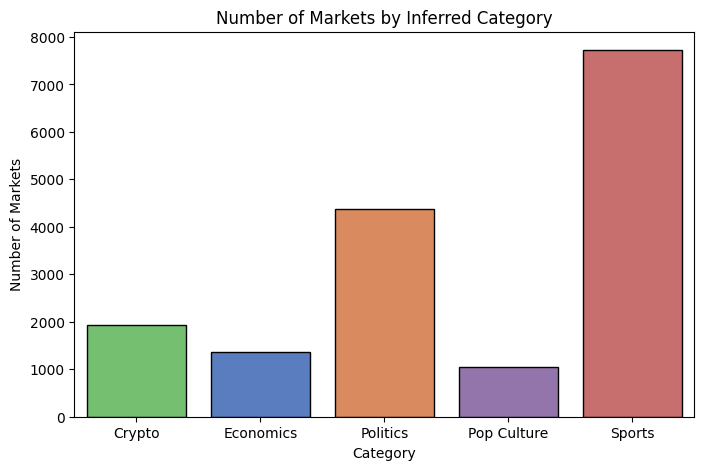

In [ ]:
summary = df_tidied.groupby('category').agg(
    market_count=('market_id', 'count'),
    total_volume=('market_volume', 'sum'),
    mean_volume=('market_volume', 'mean'),
    median_volume=('market_volume', 'median'),
    median_spread=('spread', 'median')
)

chi2_stat, p_val = stats.chisquare(summary['market_count'])
print(f"Chi-Square Statistic: {chi2_stat:.2f}, p-value: {p_val:.4e}")
display(summary.round(2))

plt.figure(figsize=(8, 5))
sns.countplot(data=df_tidied, x='category', hue='category', order=summary.index, palette='muted', edgecolor='black', legend=False)
plt.title('Number of Markets by Inferred Category')
plt.xlabel('Category')
plt.ylabel('Number of Markets')
plt.show()

**Conclusion 1:** Since *p* < 0.0001, we reject the null hypothesis. Market counts across our inferred categories are heavily skewed, with `Sports` and `Politics` having far more markets in the cleaned subset than `Crypto`, `Economics`, or `Pop Culture`. However, `Sports` has the lowest median trading volume per market (\$1,268.19) and the widest median bid-ask spread (0.07). In contrast, `Pop Culture` has the highest median trading volume (\$12,013.54) and the tightest median spread (0.02), while `Politics` and `Economics` also exhibit tighter median spreads (0.03).




### 3.2 Trading Volume & Outliers Across Categories (Kruskal-Wallis Test)

Looking at our summary table, the average trading volume is much higher than the median in every category. This happens because a small number of markets have extremely high trading volumes, sometimes reaching tens of millions of dollars.

To see whether trading volume differs across categories, we use the non-parametric **Kruskal-Wallis test**. This test compares the rankings of values across multiple groups and works well when the data contains large outliers.

We also use a $\log_{10}$ scale for our boxplot so that the differences between markets are easier to see.

- **Null Hypothesis ($H_0$):** Trading volumes follow the same distribution across all five categories.
- **Alternative Hypothesis ($H_A$):** At least one category has a different trading-volume distribution.



Kruskal-Wallis Statistic: 752.92, p-value: 1.2092e-161


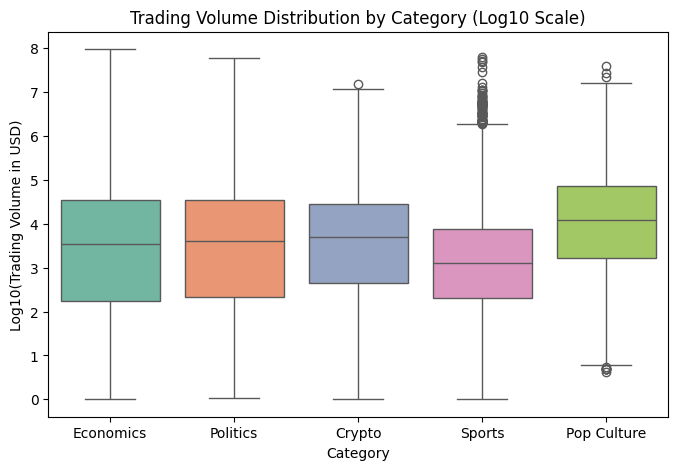

In [ ]:
df_tidied['log_volume'] = np.log10(df_tidied['market_volume'])

groups = [group['market_volume'].values for _, group in df_tidied.groupby('category')]
kw_stat, kw_p = stats.kruskal(*groups)
print(f"Kruskal-Wallis Statistic: {kw_stat:.2f}, p-value: {kw_p:.4e}")

plt.figure(figsize=(8, 5))
sns.boxplot(data=df_tidied, x='category', y='log_volume', hue='category', palette='Set2', legend=False)
plt.title('Trading Volume Distribution by Category (Log10 Scale)')
plt.xlabel('Category')
plt.ylabel('Log10(Trading Volume in USD)')
plt.show()

**Conclusion 2:** The Kruskal-Wallis test yields $p < 0.0001$, so we reject the null hypothesis. This suggests that trading volume is not distributed the same way across all five categories, although the test doesn't tell us exactly which categories differ.

The boxplot also shows that every category has some unusually high-volume markets, especially `Sports` and `Politics`.


### 3.3 Feature Correlations (Spearman Rank Correlation)

Finally, we check how our numerical features (`log_volume`, `log_liquidity`, `spread`, `duration_days`, and `commentCount`) are associated with one another. Because financial metrics are skewed and contain outliers, we use **Spearman Rank Correlation** ($\rho$).

Correlation values range from -1 to 1, where positive values indicate that two variables tend to increase together, negative values indicate that one tends to decrease as the other increases, and values near zero indicate little relationship.

A correlation does not necessarily mean that one variable causes another to change.


Spearman Correlation (Liquidity vs. Volume): r = 0.3230, p-value: 0.0000e+00


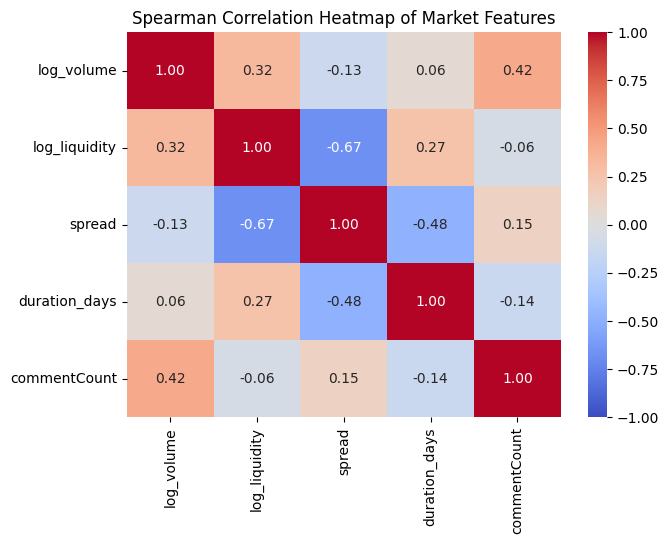

In [ ]:
df_tidied['log_liquidity'] = np.log10(df_tidied['market_liquidity'])

r_val, r_p = stats.spearmanr(df_tidied['market_liquidity'], df_tidied['market_volume'])
print(f"Spearman Correlation (Liquidity vs. Volume): r = {r_val:.4f}, p-value: {r_p:.4e}")

corr_cols = ['log_volume', 'log_liquidity', 'spread', 'duration_days', 'commentCount']
corr_matrix = df_tidied[corr_cols].corr(method='spearman')

plt.figure(figsize=(7, 5))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Spearman Correlation Heatmap of Market Features')
plt.show()


**Conclusion 3:** Trading volume has a moderate positive correlation with comment count ($\rho = 0.42$) and liquidity ($\rho = 0.32$). This means markets with more trading activity also tend to have more comments and higher liquidity.

Liquidity also has a strong negative correlation with bid-ask spread ($\rho = -0.67$), meaning markets with higher liquidity tend to have smaller spreads.

Meanwhile, volume has a weak negative correlation with spread ($\rho = -0.13$) and almost no correlation with market duration ($\rho = 0.06$). Overall, liquidity and comment count appear more closely related to trading volume than market duration does.
